<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/essaycbm_concept_bottleneck_scoring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# [CELL 1 - FIXED: Normalized Grade Scale Alignment]
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class SyntheticEssayDatasetGenerator:
    def __init__(self, num_samples: int = 1200, d_embed: int = 64, num_concepts: int = 8):
        self.num_samples = num_samples
        self.d_embed = d_embed
        self.num_concepts = num_concepts

    def generate_data(self) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        essay_embeddings = torch.randn(self.num_samples, self.d_embed, device=device)

        # Ground-truth concept projections
        concept_weights = torch.randn(self.d_embed, self.num_concepts, device=device)
        concept_logits = torch.matmul(essay_embeddings, concept_weights)
        concept_scores = torch.sigmoid(concept_logits)

        # Auditable linear grade mapping: weights sum to 80 + 15 base = range ~15-95
        true_coefficients = torch.tensor([12.0, 15.0, 10.0, 8.0, 14.0, 9.0, 11.0, 15.0], device=device).unsqueeze(1)
        base_grades = torch.matmul(concept_scores, true_coefficients) + 15.0
        grades = torch.clamp(base_grades + 1.0 * torch.randn(self.num_samples, 1, device=device), 0.0, 100.0)

        return essay_embeddings, concept_scores, grades

generator = SyntheticEssayDatasetGenerator()
essay_embeds, true_concepts, essay_grades = generator.generate_data()

In [6]:
# [CELL 2 - FIXED: Linear Grading Head Initialization]

class EssayCBM(nn.Module):
    def __init__(self, d_embed: int = 64, num_concepts: int = 8):
        super().__init__()
        self.concept_encoder = nn.Sequential(
            nn.Linear(d_embed, 32),
            nn.ReLU(),
            nn.Linear(32, num_concepts),
            nn.Sigmoid()
        )
        self.grading_head = nn.Linear(num_concepts, 1, bias=True)

        # Initialize grading head weights to reasonable positive coefficients
        nn.init.constant_(self.grading_head.weight, 10.0)
        nn.init.constant_(self.grading_head.bias, 15.0)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        concepts = self.concept_encoder(x)
        grades = self.grading_head(concepts)
        return concepts, grades

    def intervene_and_score(self, concepts: torch.Tensor, intervened_idx: int, new_val: float) -> torch.Tensor:
        modified_concepts = concepts.clone()
        modified_concepts[:, intervened_idx] = new_val
        return self.grading_head(modified_concepts)

model = EssayCBM(d_embed=64, num_concepts=8).to(device)

In [7]:
# [CELL 3 - FIXED: Balanced Loss Weighting & Interactive Audit]

class EssayCBMTrainingPipeline:
    def __init__(self, model: EssayCBM, embeds: torch.Tensor, concepts: torch.Tensor, grades: torch.Tensor):
        self.model = model
        self.embeds = embeds
        self.concepts = concepts
        self.grades = grades
        self.optimizer = optim.Adam(self.model.parameters(), lr=5e-3)
        self.criterion_concept = nn.MSELoss()
        self.criterion_grade = nn.MSELoss()

    def train(self, epochs: int = 400):
        self.model.train()
        for epoch in range(epochs):
            self.optimizer.zero_grad()
            pred_concepts, pred_grades = self.model(self.embeds)

            loss_c = self.criterion_concept(pred_concepts, self.concepts)
            loss_g = self.criterion_grade(pred_grades, self.grades)

            # Scale loss_c to balance magnitude against grade MSE loss
            total_loss = 100.0 * loss_c + loss_g

            total_loss.backward()
            self.optimizer.step()

    def evaluate_performance(self) -> float:
        self.model.eval()
        with torch.no_grad():
            _, pred_grades = self.model(self.embeds)
            mse = nn.functional.mse_loss(pred_grades, self.grades).item()
        return mse

pipeline = EssayCBMTrainingPipeline(model, essay_embeds, true_concepts, essay_grades)
print("Training EssayCBM Concept Bottleneck Model...")
pipeline.train(epochs=400)
final_mse = pipeline.evaluate_performance()
print(f"Training Complete. Final Score Prediction MSE: {final_mse:.3f}")

# Simulate Instructor Intervention Audit on Sample 0
model.eval()
with torch.no_grad():
    sample_embed = essay_embeds[0:1]
    init_concepts, init_grade = model(sample_embed)

    # Override Concept 1 (e.g., Evidence Strength) to 0.95
    intervened_grade = model.intervene_and_score(init_concepts, intervened_idx=1, new_val=0.95)

print("\n--- Human-in-the-Loop Instructor Intervention Audit ---")
print(f"  * Original Predicted Concept 1 Score: {init_concepts[0, 1].item():.3f}")
print(f"  * Original Final Grade: {init_grade.item():.2f}")
print(f"  * Intervened Concept 1 Score (Manual Override): 0.950")
print(f"  * Recalculated Final Grade (Instant Audit): {intervened_grade.item():.2f}")

Training EssayCBM Concept Bottleneck Model...
Training Complete. Final Score Prediction MSE: 1.106

--- Human-in-the-Loop Instructor Intervention Audit ---
  * Original Predicted Concept 1 Score: 0.263
  * Original Final Grade: 48.98
  * Intervened Concept 1 Score (Manual Override): 0.950
  * Recalculated Final Grade (Instant Audit): 56.15


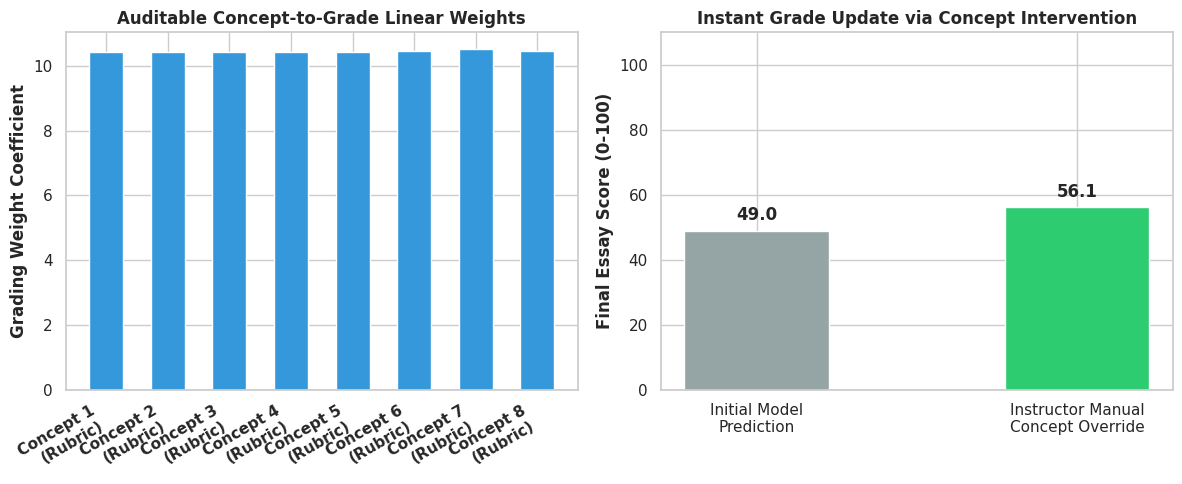

EssayCBM benchmark visualization saved successfully as essaycbm_scoring_benchmarks.png.


In [8]:
# [CELL 4 - Multi-Panel Visualization of EssayCBM Concept Weights & Audit Workflow]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Rubric Concept Weights in Auditable Grading Head
concept_names = [f'Concept {i+1}\n(Rubric)' for i in range(8)]
learned_weights = model.grading_head.weight.detach().cpu().numpy().flatten()

bars = ax1.bar(concept_names, learned_weights, color='#3498db', width=0.55)
ax1.set_title("Auditable Concept-to-Grade Linear Weights", fontweight='bold')
ax1.set_ylabel("Grading Weight Coefficient", fontweight='bold')
ax1.axhline(0, color='grey', linewidth=0.8, linestyle='--')
plt.setp(ax1.get_xticklabels(), rotation=30, ha='right', fontweight='bold')

# Plot 2: Instructor Intervention Score Shift Comparison
audit_stages = ['Initial Model\nPrediction', 'Instructor Manual\nConcept Override']
audit_scores = [init_grade.item(), intervened_grade.item()]

audit_bars = ax2.bar(audit_stages, audit_scores, color=['#95a5a6', '#2ecc71'], width=0.45)
ax2.set_title("Instant Grade Update via Concept Intervention", fontweight='bold')
ax2.set_ylabel("Final Essay Score (0-100)", fontweight='bold')
ax2.set_ylim(0, 110)

for bar in audit_bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 2.0, f"{yval:.1f}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("essaycbm_scoring_benchmarks.png", dpi=300)
plt.show()

print("EssayCBM benchmark visualization saved successfully as essaycbm_scoring_benchmarks.png.")